# Lab 4.1 · Influence, Communities and Homophily
**Chapter 4 · Social Network Analytics I**

**Goal:** compute influence, communities and homophily — first on the karate club, then on the EV mention network.
**Data:** `nx.karate_club_graph()` · `data/ev_mentions.csv` (directed, weighted, synthetic) · `data/ev_users.csv`.

📖 Interactive study guide: [Chapter 4](https://mehrdadjalali-ai.github.io/SocialMediaAnayltics/interactive/Chapter4_Networks_Influence_Communities.html) — every karate-club number is computed live there.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUTD = ROOT / "data", ROOT / "outputs"
OUTD.mkdir(exist_ok=True)
SEED = 42
import pandas as pd, networkx as nx, matplotlib.pyplot as plt

## Walkthrough · build, describe, draw

In [2]:
G = nx.karate_club_graph()
print(G.number_of_nodes(), G.number_of_edges())        # 34, 78
print(round(nx.density(G), 3), round(nx.average_clustering(G), 3))
deg = dict(G.degree()); btw = nx.betweenness_centrality(G); pr = nx.pagerank(G)
top5 = lambda d: sorted(d, key=d.get, reverse=True)[:5]
print("degree", top5(deg), "| betweenness", top5(btw), "| pagerank", top5(pr))

34 78
0.139 0.571
degree [33, 0, 32, 2, 1] | betweenness [0, 33, 32, 2, 31] | pagerank [33, 0, 32, 2, 1]


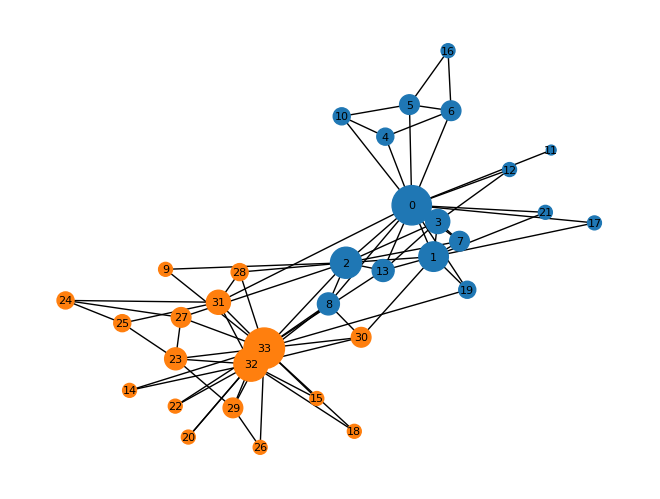

In [3]:
pos = nx.spring_layout(G, seed=3)                       # fixed seed = reproducible picture
colors = ["tab:blue" if G.nodes[n]["club"] == "Mr. Hi" else "tab:orange" for n in G]
nx.draw(G, pos, node_size=[50 * d for d in deg.values()], node_color=colors, with_labels=True, font_size=8)
plt.show()

In [4]:
comms = nx.community.louvain_communities(G, seed=42, resolution=1.0)
print(len(comms), round(nx.community.modularity(G, comms), 3))      # 4, 0.427
print(round(nx.attribute_assortativity_coefficient(G, "club"), 3))  # 0.718
nx.write_gexf(G, OUTD / "karate.gexf")                              # open in Gephi

4 0.427
0.718


## Challenge 1 · Influence

Top 5 by degree, betweenness, closeness and PageRank. Which node ranks very differently across measures — and **why**?

> 💡 **Hint:** Build a DataFrame with one column per centrality and use `.rank(ascending=False)`.

In [5]:
# Challenge 1 — your code here


**Your interpretation (Challenge 1):** _write 2–3 sentences — what did you find, and what could explain it?_

## Challenge 2 · Communities

Run Louvain at **two resolutions** (e.g. 0.5 and 1.5). Compare each partition with the real club split (cross-tab) and modularity. Find one **bridge** user.

> 💡 **Hint:** Count cross-group edges per node: `sum(G.nodes[u]['club'] != G.nodes[v]['club'] for v in G[u])`.

In [6]:
# Challenge 2 — your code here


**Your interpretation (Challenge 2):** _write 2–3 sentences — what did you find, and what could explain it?_

## Challenge 3 · Homophily

Compute assortativity for **two** attributes (club, degree). State one limitation of your interpretation.

> 💡 **Hint:** A single snapshot cannot separate homophily (selection) from influence (contagion).

In [7]:
# Challenge 3 — your code here


**Your interpretation (Challenge 3):** _write 2–3 sentences — what did you find, and what could explain it?_

## Transfer · the EV mention network

In [8]:
m = pd.read_csv(DATA / "ev_mentions.csv"); users = pd.read_csv(DATA / "ev_users.csv")
E = nx.from_pandas_edgelist(m, "source", "target", ["weight"], create_using=nx.DiGraph)
nx.set_node_attributes(E, users.set_index("user_id")["lang"].to_dict(), "lang")
print(E.number_of_nodes(), E.number_of_edges(), "weakly connected parts:", nx.number_weakly_connected_components(E))
indeg = dict(E.in_degree(weight="weight"))
print("most mentioned:", sorted(indeg, key=indeg.get, reverse=True)[:5])

260 1208 weakly connected parts: 1
most mentioned: ['u064', 'u137', 'u196', 'u184', 'u236']


In [9]:
# TODO: repeat Challenges 1–2 on E (use E.to_undirected() for Louvain),
# name each community from its content (users.group, sentiment of mentions) — never from the colour,
# then save the graph for Chapter 5:
nx.write_gexf(E, OUTD / "ev_mentions.gexf")